# 4. Context and fairness

**Questions.** Where does each barangay sit among all Metro Manila residents, and how unequal is access inside each (RQ5)?

**Method.**

- **Percentile.** For each category, the share of all Metro Manila residents whose walk is longer than the barangay's median resident's (for M4, who have fewer categories within 15 minutes). Above 50% is better than the Metro Manila median.
- **Similar density.** The same share among residents of barangays in the same people-weighted tenth of density, because density drives proximity.
- **Neighbours.** Barangay 136 against the other 258 barangays of Tondo; Loyola Heights against the rest of Quezon City; Oranbo against the rest of Pasig.
- **Fairness inside each barangay.** The P90/P10 ratio of walking times, and the share of residents within the 10-minute minimum (notebook 1).

In [1]:
import sys
from pathlib import Path

# The notebooks import their logic from src/: the shared helpers and the analysis functions.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "shared").is_dir())
for folder in ("src/shared", "src/03_analyse"):
    sys.path.insert(0, str(ROOT / folder))

import charts
import measures
import pandas as pd
from common import TABLES
from IPython.display import Image

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)
AREAS = measures.STUDY + ["Metro Manila"]
m = pd.read_csv(TABLES / "measures.csv")
w, b = measures.load()

In [2]:
c = measures.context_table(w)
c.to_csv(TABLES / "context.csv", index=False, float_format="%.6g")
c.round(2)

,barangay,metric,median,share_metro_worse,density_tenth,share_similar_density_worse
0,Barangay 136,M1 food_retail,1.72,0.85,7,0.81
1,Barangay 136,M1 palengke,12.97,0.38,7,0.25
2,Barangay 136,M1 pharmacy,2.26,0.87,7,0.84
3,Barangay 136,M1 primary_care,2.49,0.83,7,0.76
4,Barangay 136,M1 hospital,10.49,0.57,7,0.54
5,Barangay 136,M1 public_elementary,3.75,0.90,7,0.87
6,Barangay 136,M1 public_high,3.98,0.95,7,0.94
7,Barangay 136,M1 open_space,14.36,0.40,7,0.35
8,Barangay 136,M1 transit,2.86,0.66,7,0.53
9,Barangay 136,M4,9.00,0.75,7,0.64


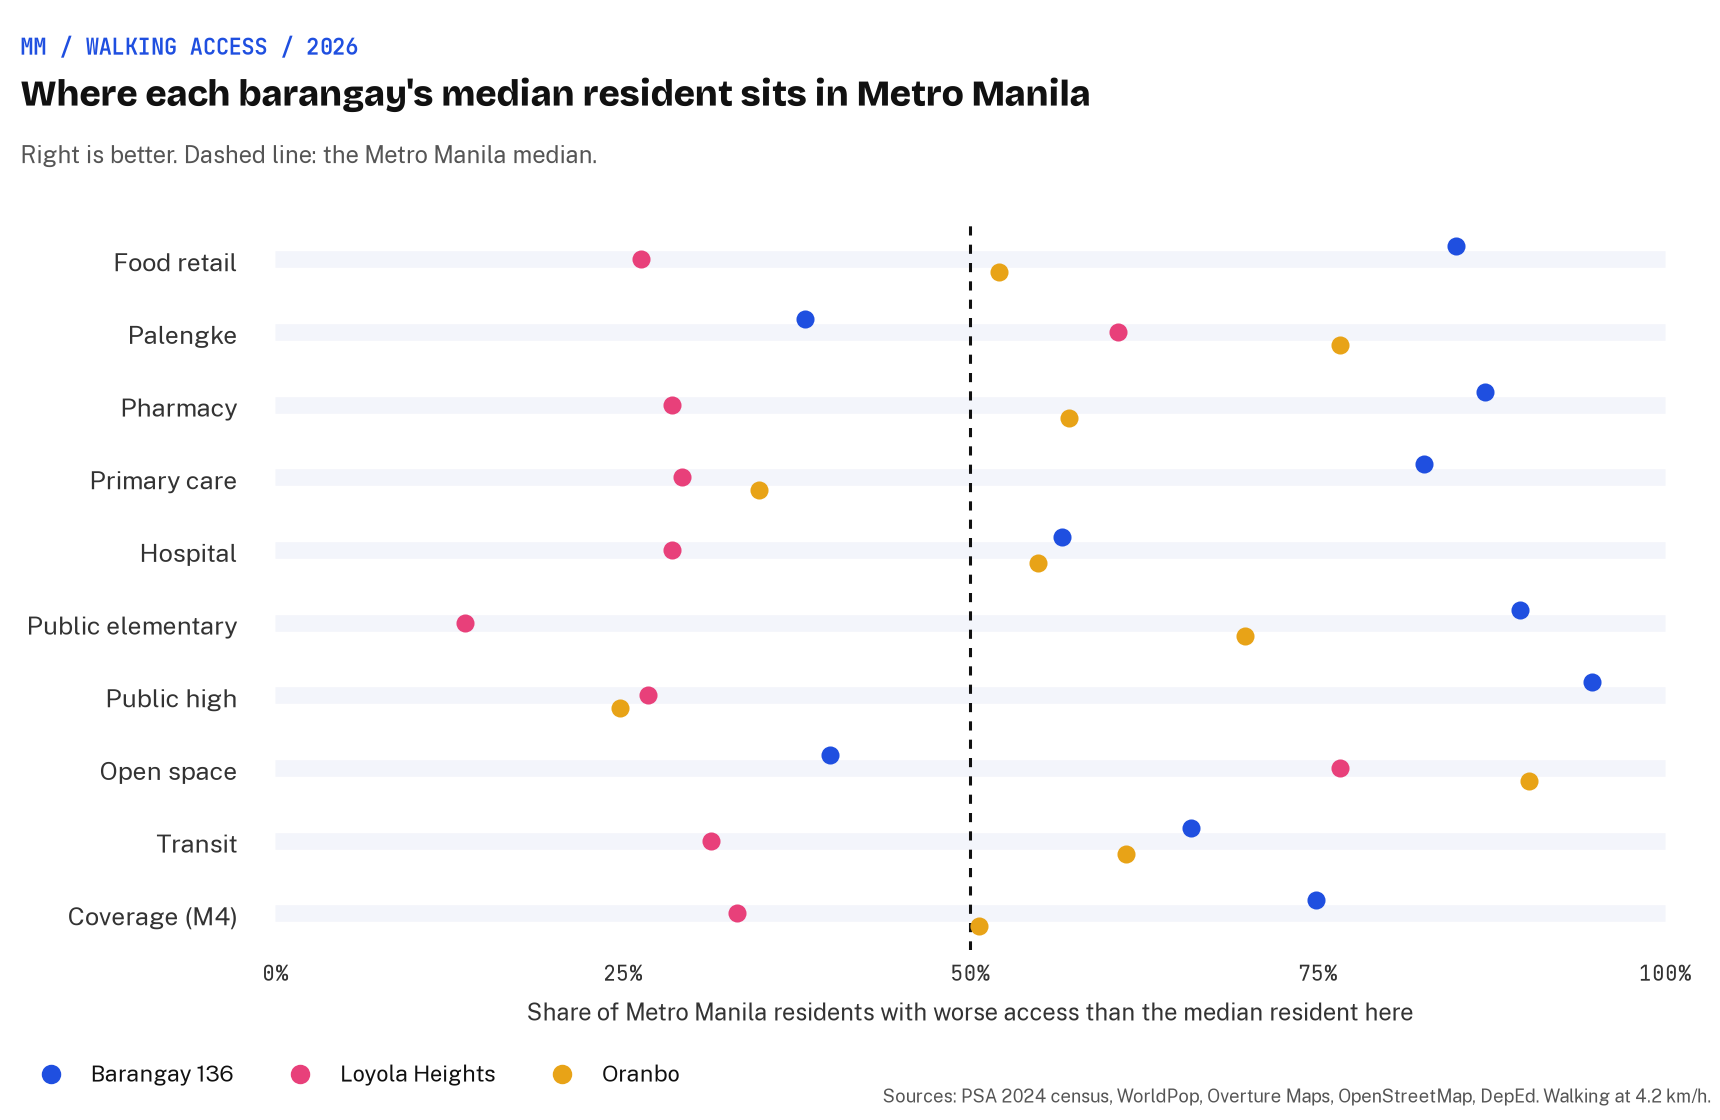

In [3]:
Image(charts.context_chart(c))

**Reading.** Barangay 136's median resident has better access than most of Metro Manila for food, pharmacies, clinics and both public school levels (more than 80% of residents walk further), and worse access than most for the palengke and open space (38% and 40% walk further). Oranbo's median resident is above the Metro Manila median for open space (90%), the palengke (77%) and elementary schools (70%) and close to it for food, pharmacies, hospitals and transit, but below it for primary care (35%) and public high schools (25%). Loyola Heights' median resident is below the Metro Manila median for seven of the nine categories, and for public elementary schools only 14% of Metro Manila walks further. Against barangays of similar density (Loyola Heights and Oranbo are both in the least dense tenth), Loyola Heights moves up but stays below the middle on most categories, and Oranbo moves well above it.

## Beside the neighbours

Median minutes (M1) and mean categories within 15 minutes (M4).

In [4]:
NEIGHBOURS = [
    "Barangay 136",
    "Tondo, other 258 barangays",
    "Loyola Heights",
    "Quezon City, other barangays",
    "Oranbo",
    "City of Pasig, other barangays",
]
n1 = m[(m.measure == "M1") & (m.stat == "median_min") & m.area.isin(NEIGHBOURS)].pivot_table(
    index="category", columns="area", values="value", sort=False
)[NEIGHBOURS]
n4 = (
    m[(m.measure == "M4") & (m.stat == "mean_categories_within_15min") & m.area.isin(NEIGHBOURS)]
    .set_index("area")
    .value.rename("M4 mean")[NEIGHBOURS]
)
pd.concat([n1, n4.to_frame().T]).round(1)

area,Barangay 136,"Tondo, other 258 barangays",Loyola Heights,"Quezon City, other barangays",Oranbo,"City of Pasig, other barangays"
food_retail,1.7,3.1,6.0,4.2,3.7,3.6
palengke,13.0,8.1,8.8,11.8,6.4,11.3
pharmacy,2.3,4.1,7.9,6.0,4.7,4.9
primary_care,2.5,4.0,7.3,5.8,6.6,4.6
hospital,10.5,7.3,17.2,13.0,10.8,10.6
public_elementary,3.7,6.3,20.9,12.0,6.7,9.9
public_high,4.0,9.0,20.6,16.5,21.4,13.5
open_space,14.4,13.5,6.9,11.2,3.9,10.1
transit,2.9,2.2,7.8,5.0,3.3,4.3
food_retail_no_convenience,1.8,4.2,7.1,6.2,6.8,5.5


**Reading.** Each barangay against its own area: Barangay 136 is quicker than the rest of Tondo for food, pharmacies, clinics and schools, and slower for the palengke (13.0 against 8.1 minutes), hospitals, open space and transit, with a higher mean coverage (8.7 against 8.0). Loyola Heights is slower than the rest of Quezon City for everything except the palengke and open space, and its coverage is a little lower (6.5 against 6.8). Oranbo is quicker than the rest of Pasig for the palengke, open space, elementary schools and transit, and slower for primary care and public high schools, with coverage just above it (7.7 against 7.5).

## Inequality inside each barangay

P90/P10 ratio of the walk to the nearest service.

In [5]:
m[(m.measure == "M1") & m.stat.isin(["p90_p10_ratio"]) & m.area.isin(measures.STUDY + ["Metro Manila"])].pivot_table(
    index=["category", "stat"], columns="area", values="value", sort=False
)[measures.STUDY + ["Metro Manila"]].round(1)

,area,Barangay 136,Loyola Heights,Oranbo,Metro Manila
category,stat,,,,
food_retail,p90_p10_ratio,5.3,7.8,3.2,6.8
palengke,p90_p10_ratio,1.2,4.8,3.7,6.1
pharmacy,p90_p10_ratio,3.8,4.6,5.6,6.5
primary_care,p90_p10_ratio,1.8,6.6,2.7,6.4
hospital,p90_p10_ratio,1.4,4.9,4.5,6.1
public_elementary,p90_p10_ratio,2.2,3.2,3.9,6.7
public_high,p90_p10_ratio,2.1,2.4,2.0,6.1
open_space,p90_p10_ratio,1.2,5.3,9.5,6.2
transit,p90_p10_ratio,2.9,8.9,7.1,21.6


**Reading.** Inside each barangay, access is most even in Barangay 136 (a P90/P10 ratio of 1.2 to 5.3), as a one-block barangay must be. Loyola Heights is the most unequal of the three for food (7.8) and transit (8.9), Oranbo for open space (9.5). Inside each barangay access is more even than across Metro Manila for every category except food and primary care in Loyola Heights and open space in Oranbo.

## For the web map

People-weighted measures per H3 resolution-10 hexagon, saved to the gitignored `data/work/` for PR 4; no hexagon is published here.

In [6]:
from common import WORK

h = measures.hex_table(w)
h.to_parquet(WORK / "hex_measures.parquet", index=False)
print(f"{len(h):,} hexagons, median {h.people.median():.0f} people each")

35,954 hexagons, median 296 people each
